# EDA: сегментация очагов кожи (ISIC 2018, Task 1)

**Датасет:** [ISIC 2018 Task 1](https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation) (Kaggle, CC0).

**Цель:** изучить данные - целостность, разрешения, геометрию очагов, яркость, цвет, артефакты, дубликаты - и понять, **что именно в них нужно нормализовать**.

> Первый запуск считает признаки (≈7 минут) и кэширует их в `../data/processed/`.

## 1. Целостность

In [27]:
import math
import os
from collections import Counter

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from PIL import Image
from tqdm import tqdm

# --- единый стиль графиков: один основной цвет, акцент, тихая сетка ---
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#cfcfca", "grid.color": "#e6e6e2", "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.labelsize": 10, "figure.dpi": 100,
})

ROOT = "../data/raw/task_1_2_2018"
IMAGES_DIR = f"{ROOT}/ISIC2018_Task1-2_Training_Input"
MASKS_DIR = f"{ROOT}/ISIC2018_Task1_Training_GroundTruth"

PROCESSED_DIR = "../data/processed"
FEATURES_PATH = f"{PROCESSED_DIR}/eda_features.csv"   # кэш табличных признаков
THUMBS_PATH = f"{PROCESSED_DIR}/eda_mask_thumbs.npy"  # кэш уменьшенных масок 64x64
SPLITS_PATH = f"{PROCESSED_DIR}/eda_splits.csv"
os.makedirs(PROCESSED_DIR, exist_ok=True)

plt.rcParams["figure.max_open_warning"] = 0

RANDOM_STATE = 42
ANALYSIS_SIDE = 512   # длинная сторона, до которой уменьшаем кадры для тяжёлых расчётов
THUMB = 64            # размер уменьшенных масок для карт приоров


def spearman(a, b):
    """Корреляция Спирмена без scipy: Пирсон по рангам."""
    return a.rank().corr(b.rank())

In [28]:
image_files = sorted(f for f in os.listdir(IMAGES_DIR) if f.lower().endswith(".jpg"))
mask_files = sorted(f for f in os.listdir(MASKS_DIR) if f.lower().endswith("_segmentation.png"))
print(f"Изображений: {len(image_files)}, масок: {len(mask_files)}")

# Сопоставляем строго по ID, а не по порядку в списках
image_by_id = {os.path.splitext(f)[0]: f for f in image_files}
mask_by_id = {f[: -len("_segmentation.png")]: f for f in mask_files}

images_without_masks = sorted(set(image_by_id) - set(mask_by_id))
masks_without_images = sorted(set(mask_by_id) - set(image_by_id))
print(f"Картинок без масок: {len(images_without_masks)}, масок без картинок: {len(masks_without_images)}")

rows, mismatched = [], []
for id_ in tqdm(sorted(set(image_by_id) & set(mask_by_id))):
    image_path = os.path.join(IMAGES_DIR, image_by_id[id_])
    mask_path = os.path.join(MASKS_DIR, mask_by_id[id_])
    with Image.open(image_path) as im:
        img_size, img_mode = im.size, im.mode
    with Image.open(mask_path) as m:
        mask_size, mask_mode = m.size, m.mode
    if img_size != mask_size:
        mismatched.append({"id": id_, "image_size": img_size, "mask_size": mask_size})
        continue
    rows.append({"id": id_, "image_path": image_path, "mask_path": mask_path,
                 "width": img_size[0], "height": img_size[1],
                 "img_mode": img_mode, "mask_mode": mask_mode})

df_dataset = pd.DataFrame(rows)
print(f"Несовпадений размеров: {len(mismatched)}")
print(f"Режимы изображений: {dict(Counter(df_dataset['img_mode']))}; режимы масок: {dict(Counter(df_dataset['mask_mode']))}")
print(f"Итого валидных пар: {len(df_dataset)}")

Изображений: 2594, масок: 2594
Картинок без масок: 0, масок без картинок: 0


100%|██████████| 2594/2594 [00:02<00:00, 1103.36it/s]


Несовпадений размеров: 0
Режимы изображений: {'RGB': 2594}; режимы масок: {'L': 2594}
Итого валидных пар: 2594


> 2594 изображения, у каждого есть маска, размеры совпадают; изображения RGB, маски одноканальные (`L`).

## 2. Признаки
Геометрия и форма масок, цвет, яркость, артефакты и perceptual hash считаются на копиях с длинной стороной 512 px (площадь очага - по маске в полном разрешении).

In [29]:
def read_image_reduced(path, width, height, target=ANALYSIS_SIDE):
    """JPEG сразу в уменьшенном виде (DCT-scaling), длинная сторона не меньше target."""
    long_side = max(width, height)
    for factor, flag in ((8, cv2.IMREAD_REDUCED_COLOR_8),
                         (4, cv2.IMREAD_REDUCED_COLOR_4),
                         (2, cv2.IMREAD_REDUCED_COLOR_2)):
        if long_side / factor >= target:
            return cv2.imread(path, flag | cv2.IMREAD_IGNORE_ORIENTATION)
    return cv2.imread(path, cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)


def estimate_illumination(img, p=6, mask=None):
    """Shades of Gray: цвет источника света нормой Минковского, нормированный на L2 (белый = 1/sqrt(3) = 0.577).
    mask (bool HxW) - считать только по этим пикселям. OpenCV хранит BGR."""
    pixels = (img[mask] if mask is not None else img.reshape(-1, 3)).astype(np.float64)
    b, g, r = np.power(np.mean(np.power(pixels, p), axis=0), 1 / p)
    norm = np.sqrt(r**2 + g**2 + b**2)
    return r / norm, g / norm, b / norm


def dhash(gray, size=8):
    """Difference hash (64 бит) как hex-строка - для поиска дубликатов."""
    small = cv2.resize(gray, (size + 1, size), interpolation=cv2.INTER_AREA)
    bits = (small[:, 1:] > small[:, :-1]).flatten()
    return f"{int(np.packbits(bits).view('>u8')[0]):016x}"


def corner_dark_fraction(gray, frac=0.1, thr=30):
    """Доля тёмных пикселей в четырёх угловых патчах - прокси виньетки / чёрной рамки дерматоскопа."""
    h, w = gray.shape
    s = max(1, int(min(h, w) * frac))
    corners = [gray[:s, :s], gray[:s, -s:], gray[-s:, :s], gray[-s:, -s:]]
    return float(np.mean([(c < thr).mean() for c in corners]))


def extract_features(row):
    """Все признаки одной пары. Маска читается в полном разрешении (для точной площади),
    геометрия и цвет считаются на копии с длинной стороной ANALYSIS_SIDE."""
    mask_full = cv2.imread(row.mask_path, cv2.IMREAD_UNCHANGED)
    is_binary = bool(set(np.unique(mask_full).tolist()) <= {0, 255})
    lesion = mask_full > 127
    area_pct = float(lesion.mean() * 100)

    s = min(1.0, ANALYSIS_SIDE / max(row.width, row.height))
    nw, nh = max(1, round(row.width * s)), max(1, round(row.height * s))
    mask = cv2.resize(lesion.astype(np.uint8), (nw, nh), interpolation=cv2.INTER_NEAREST)
    thumb = cv2.resize(mask.astype(np.float32), (THUMB, THUMB), interpolation=cv2.INTER_AREA)

    # --- топология и форма ---
    min_area = 0.0005 * nw * nh
    _, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    n_components = int((areas >= min_area).sum())
    contours_all, hier = cv2.findContours(mask, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    n_holes = 0 if hier is None else sum(
        1 for i, c in enumerate(contours_all) if hier[0][i][3] != -1 and cv2.contourArea(c) >= min_area)
    touches_border = bool(mask[0].any() or mask[-1].any() or mask[:, 0].any() or mask[:, -1].any())

    ys, xs = np.nonzero(mask)
    out = {
        "id": row.id, "mask_is_binary": is_binary, "lesion_area_pct": area_pct,
        "n_components": n_components, "n_holes": n_holes, "touches_border": touches_border,
        "cx": xs.mean() / nw if xs.size else np.nan, "cy": ys.mean() / nh if ys.size else np.nan,
    }
    ext, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if ext:
        c = max(ext, key=cv2.contourArea)
        a, p = cv2.contourArea(c), cv2.arcLength(c, True)
        hull_a = cv2.contourArea(cv2.convexHull(c))
        x, y, bw, bh = cv2.boundingRect(c)
        out.update({
            "solidity": a / hull_a if hull_a > 0 else np.nan,          # 1 = выпуклая форма
            "circularity": 4 * np.pi * a / (p * p) if p > 0 else np.nan,  # 1 = круг
            "bbox_w": bw / nw, "bbox_h": bh / nh,
            "ellipse_axis_ratio": (min(cv2.fitEllipse(c)[1]) / max(cv2.fitEllipse(c)[1]))
            if len(c) >= 5 and max(cv2.fitEllipse(c)[1]) > 0 else np.nan,
        })

    # --- изображение ---
    img = read_image_reduced(row.image_path, row.width, row.height)
    img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    rgb = img[:, :, ::-1].astype(np.float64) / 255.0
    mean_rgb, std_rgb = rgb.mean(axis=(0, 1)), rgb.std(axis=(0, 1))
    out.update({"mean_r": mean_rgb[0], "mean_g": mean_rgb[1], "mean_b": mean_rgb[2],
                "std_r": std_rgb[0], "std_g": std_rgb[1], "std_b": std_rgb[2]})

    # освещение: по всему кадру и по фону
    bg = mask == 0
    out["illum_r"], out["illum_g"], out["illum_b"] = estimate_illumination(img)
    if bg.sum() > 100:
        out["illum_bg_r"], out["illum_bg_g"], out["illum_bg_b"] = estimate_illumination(img, mask=bg)
    # контраст «очаг vs окружение» в Lab (шкала OpenCV)
    if bg.sum() > 100 and mask.sum() > 100:
        lab = cv2.cvtColor(img, cv2.COLOR_BGR2Lab).astype(np.float64)
        d = lab[mask == 1].mean(axis=0) - lab[bg].mean(axis=0)
        out["lesion_dL"], out["lesion_delta_lab"] = d[0], float(np.linalg.norm(d))

    # артефакты: волосы считаем ТОЛЬКО по фону (вдали от очага), чтобы не путать с текстурой очага
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17)))
    far_bg = cv2.dilate(mask, np.ones((15, 15), np.uint8)) == 0
    out["hair_bg_frac"] = float((blackhat > 10)[far_bg].mean()) if far_bg.sum() > 100 else np.nan
    out.update({"brightness": gray.mean(), "contrast": gray.std(),
                "blur_lapvar": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
                "corner_dark": corner_dark_fraction(gray), "dhash": dhash(gray)})
    return out, thumb

In [30]:
ids_ok = False
if os.path.exists(FEATURES_PATH) and os.path.exists(THUMBS_PATH):
    features = pd.read_csv(FEATURES_PATH, dtype={"dhash": str})
    thumbs = np.load(THUMBS_PATH)
    ids_ok = list(features["id"]) == list(df_dataset["id"]) and len(thumbs) == len(features)

if ids_ok:
    print(f"Признаки загружены из кэша: {FEATURES_PATH}")
else:
    results = [extract_features(r) for r in tqdm(df_dataset.itertuples(index=False), total=len(df_dataset))]
    features = pd.DataFrame([r[0] for r in results])
    thumbs = np.stack([r[1] for r in results])
    features.to_csv(FEATURES_PATH, index=False)
    np.save(THUMBS_PATH, thumbs)
    print(f"Признаки посчитаны и сохранены: {FEATURES_PATH}")

df = df_dataset.merge(features, on="id", validate="one_to_one")
assert list(df["id"]) == list(features["id"])
df["aspect_ratio"] = df["width"] / df["height"]
df["resolution"] = df["width"].astype(str) + "x" + df["height"].astype(str)
df["r_g_ratio"] = df["illum_r"] / df["illum_g"]
print(f"Строк: {len(df)}, признаков: {df.shape[1]}, пропусков в числовых колонках: {int(df.select_dtypes('number').isna().sum().sum())}")
display(df.drop(columns=["image_path", "mask_path", "dhash"]).describe().T.round(3)[["mean", "std", "min", "50%", "max"]])

Признаки загружены из кэша: ../data/processed/eda_features.csv
Строк: 2594, признаков: 42, пропусков в числовых колонках: 0


,mean,std,min,50%,max
width,3188.266,1923.092,576.000,3008.000,6748.000
height,2166.791,1241.344,540.000,2000.000,4499.000
lesion_area_pct,21.402,20.837,0.298,13.808,98.665
n_components,1.006,0.081,1.000,1.000,3.000
n_holes,0.012,0.138,0.000,0.000,3.000
cx,0.491,0.054,0.195,0.496,0.813
cy,0.503,0.061,0.227,0.500,0.785
solidity,0.936,0.055,0.330,0.945,1.000
circularity,0.605,0.212,0.020,0.639,0.898
bbox_w,0.434,0.246,0.047,0.384,1.000


## 3. Разрешения

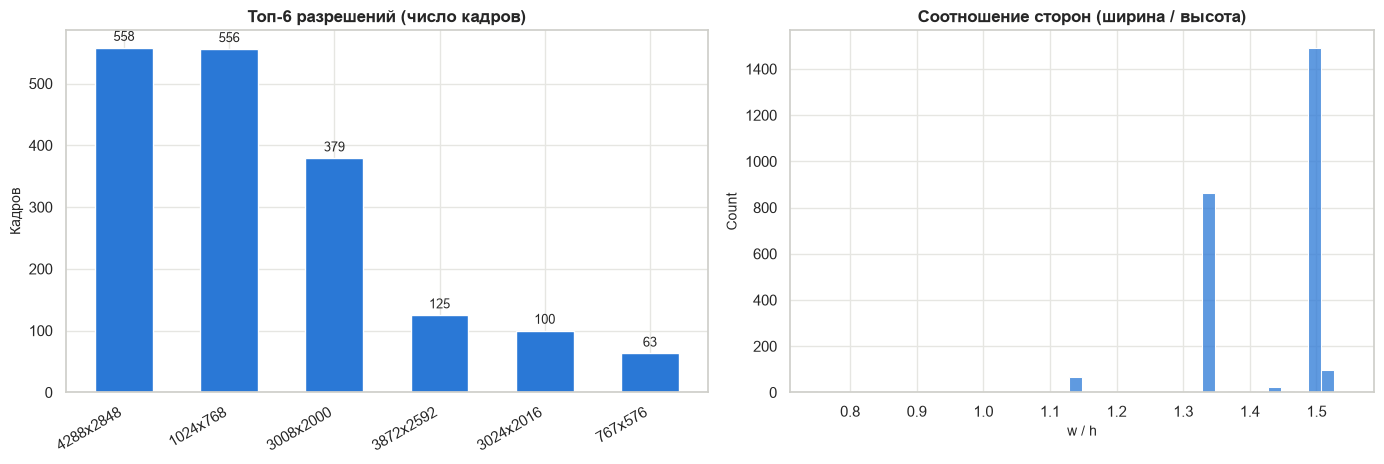

Уникальных разрешений: 206; топ-6 покрывают 68.7% датасета
Мегапиксели: медиана 6.0, min 0.38, max 30.4
Портретных кадров (w < h): 6; соотношений сторон (округл. до 0.01): 33


,n,доля
source,,
4288x2848,558,21.5%
1024x768,556,21.4%
3008x2000,379,14.6%
3872x2592,125,4.8%
3024x2016,100,3.9%
767x576,63,2.4%
other,813,31.3%


In [31]:
res_counts = df["resolution"].value_counts()
top6 = res_counts.head(6)
# «Источник» (прокси камеры/клиники): топ-6 разрешений, остальное - other
df["source"] = np.where(df["resolution"].isin(top6.index), df["resolution"], "other")
SOURCE_ORDER = list(top6.index) + ["other"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
bars = axes[0].bar(range(len(top6)), top6.values, color=BLUE, width=0.55)
axes[0].bar_label(bars, padding=3, fontsize=9)
axes[0].set_xticks(range(len(top6)), top6.index, rotation=30, ha="right")
axes[0].set_title("Топ-6 разрешений (число кадров)")
axes[0].set_ylabel("Кадров")

sns.histplot(df["aspect_ratio"], bins=40, color=BLUE, edgecolor="white", ax=axes[1])
axes[1].set_title("Соотношение сторон (ширина / высота)")
axes[1].set_xlabel("w / h")
plt.tight_layout()
plt.show()

print(f"Уникальных разрешений: {len(res_counts)}; топ-6 покрывают {top6.sum() / len(df):.1%} датасета")
print(f"Мегапиксели: медиана {(df['width'] * df['height']).median() / 1e6:.1f}, "
      f"min {(df['width'] * df['height']).min() / 1e6:.2f}, max {(df['width'] * df['height']).max() / 1e6:.1f}")
print(f"Портретных кадров (w < h): {(df['width'] < df['height']).sum()}; соотношений сторон (округл. до 0.01): {df['aspect_ratio'].round(2).nunique()}")
display(df["source"].value_counts().reindex(SOURCE_ORDER).to_frame("n").assign(доля=lambda t: (t["n"] / len(df)).map("{:.1%}".format)))

> 206 уникальных разрешений, медиана 6 Мп (0.38-30 Мп). 6 самых частых покрывают 68.7% кадров, остальные 31% - длинный хвост. Кадры почти все альбомные (портретных 6), соотношение сторон в основном 1.33 или 1.5. Разрешение ниже используется как прокси **источника** съёмки (камеры или клиники); `other` - смесь многих источников.

## 4. Геометрия очагов и масок

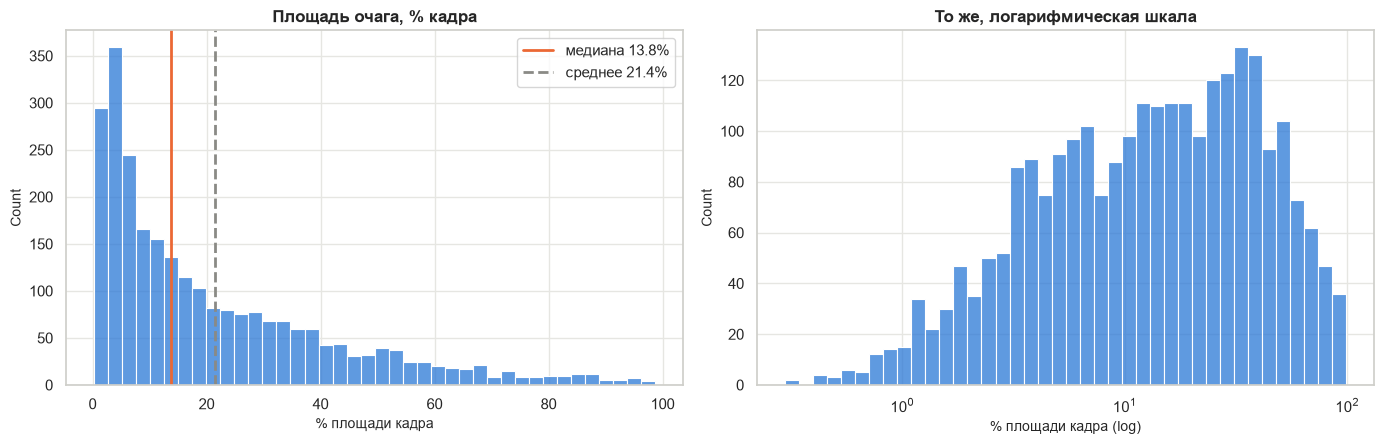

,n,доля
area_bucket,,
малые <5%,624,24.1%
средние 5-25%,1116,43.0%
крупные >25%,854,32.9%


count    2594.00
mean       21.40
std        20.84
min         0.30
1%          0.78
5%          1.55
25%         5.17
50%        13.81
75%        31.87
95%        65.18
99%        88.17
max        98.66


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sns.histplot(df["lesion_area_pct"], bins=40, color=BLUE, edgecolor="white", ax=axes[0])
axes[0].axvline(df["lesion_area_pct"].median(), color=ORANGE, lw=2, label=f"медиана {df['lesion_area_pct'].median():.1f}%")
axes[0].axvline(df["lesion_area_pct"].mean(), color=GRAY, lw=2, ls="--", label=f"среднее {df['lesion_area_pct'].mean():.1f}%")
axes[0].set_title("Площадь очага, % кадра")
axes[0].set_xlabel("% площади кадра")
axes[0].legend()

sns.histplot(df["lesion_area_pct"], bins=40, log_scale=True, color=BLUE, edgecolor="white", ax=axes[1])
axes[1].set_title("То же, логарифмическая шкала")
axes[1].set_xlabel("% площади кадра (log)")
plt.tight_layout()
plt.show()

df["area_bucket"] = pd.cut(df["lesion_area_pct"], bins=[0, 5, 25, 100], labels=["малые <5%", "средние 5-25%", "крупные >25%"])
tab = df["area_bucket"].value_counts().sort_index().to_frame("n")
tab["доля"] = (tab["n"] / len(df)).map("{:.1%}".format)
display(tab)
print(df["lesion_area_pct"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2).to_string())

> **Размер:** сильно скошен вправо: медиана 13.8% кадра при среднем 21.4%; 24% очагов <5%, 33% >25%; от 0.3% до 98.7%.

Маски строго бинарные (0/255): 100.0%; пустых масок: 0
> 1 значимой компоненты: 14 (0.5%)
Есть дыры внутри очага:  24 (0.9%)
Касается границы кадра:  253 (9.8%)


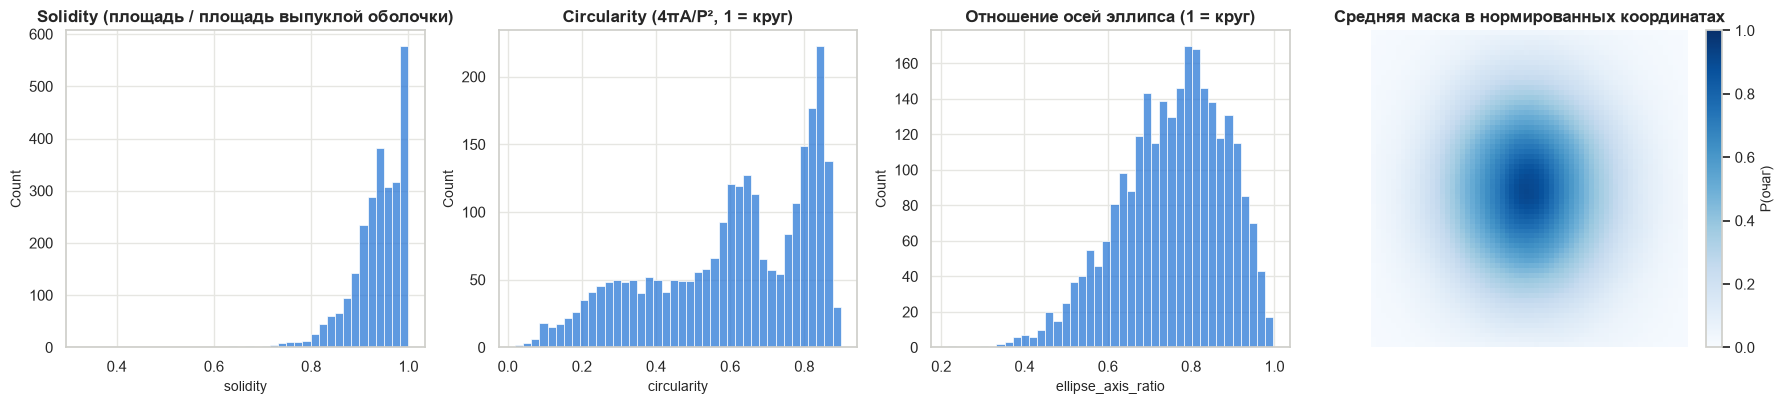

Центр очага: cx = 0.491 ± 0.054, cy = 0.503 ± 0.061
Очаг в центральной области кадра 40-60%: 84.5%


,solidity,circularity,ellipse_axis_ratio
area_bucket,,,
малые <5%,0.933,0.627,0.774
средние 5-25%,0.946,0.618,0.769
крупные >25%,0.961,0.727,0.772


In [33]:
print(f"Маски строго бинарные (0/255): {df['mask_is_binary'].mean():.1%}; пустых масок: {(df['lesion_area_pct'] == 0).sum()}")
print(f"> 1 значимой компоненты: {(df['n_components'] > 1).sum()} ({(df['n_components'] > 1).mean():.1%})")
print(f"Есть дыры внутри очага:  {(df['n_holes'] > 0).sum()} ({(df['n_holes'] > 0).mean():.1%})")
print(f"Касается границы кадра:  {df['touches_border'].sum()} ({df['touches_border'].mean():.1%})")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
sns.histplot(df["solidity"], bins=40, color=BLUE, edgecolor="white", ax=axes[0])
axes[0].set_title("Solidity (площадь / площадь выпуклой оболочки)")
sns.histplot(df["circularity"], bins=40, color=BLUE, edgecolor="white", ax=axes[1])
axes[1].set_title("Circularity (4πA/P², 1 = круг)")
sns.histplot(df["ellipse_axis_ratio"], bins=40, color=BLUE, edgecolor="white", ax=axes[2])
axes[2].set_title("Отношение осей эллипса (1 = круг)")
mean_mask = thumbs.mean(axis=0)
im = axes[3].imshow(mean_mask, cmap="Blues", vmin=0, vmax=1)
axes[3].set_title("Средняя маска в нормированных координатах")
axes[3].axis("off")
plt.colorbar(im, ax=axes[3], fraction=0.046, label="P(очаг)")
plt.tight_layout()
plt.show()

print(f"Центр очага: cx = {df['cx'].mean():.3f} ± {df['cx'].std():.3f}, cy = {df['cy'].mean():.3f} ± {df['cy'].std():.3f}")
print(f"Очаг в центральной области кадра 40-60%: {((df['cx'].between(.4, .6)) & (df['cy'].between(.4, .6))).mean():.1%}")
display(df.groupby("area_bucket", observed=True)[["solidity", "circularity", "ellipse_axis_ratio"]].median().round(3))

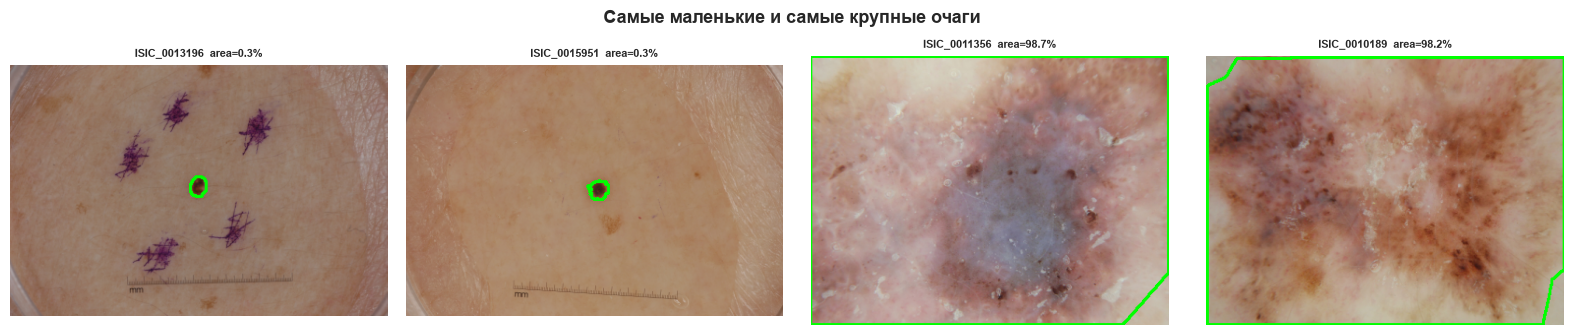

In [34]:
def load_preview(row, max_side=384):
    """Картинка + контур маски, длинная сторона max_side."""
    img = read_image_reduced(row.image_path, row.width, row.height, target=max_side)
    s = min(1.0, max_side / max(row.width, row.height))
    size = (max(1, round(row.width * s)), max(1, round(row.height * s)))
    img = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
    mask = cv2.imread(row.mask_path, cv2.IMREAD_GRAYSCALE)
    mask = (cv2.resize(mask, size, interpolation=cv2.INTER_NEAREST) > 127).astype(np.uint8)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = img.copy()
    cv2.drawContours(out, cnts, -1, (0, 255, 0), 2)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)


def show_grid(df_sub, title, ncols=4, subtitle=None):
    n = len(df_sub)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.4 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, row in zip(axes.flat, df_sub.itertuples(index=False)):
        ax.imshow(load_preview(row))
        extra = f"\n{subtitle(row)}" if subtitle else ""
        ax.set_title(f"{row.id}  area={row.lesion_area_pct:.1f}%{extra}", fontsize=8)
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


show_grid(pd.concat([df.nsmallest(2, "lesion_area_pct"), df.nlargest(2, "lesion_area_pct")]), "Самые маленькие и самые крупные очаги")

> **Маски:** все бинарные (0/255), пустых нет; 14 (0.5%) из нескольких компонент, 24 (0.9%) с дырами, 253 (9.8%) касаются границы кадра. Формы выпуклые (медиана solidity 0.945), вытянутость умеренная (оси эллипса ≈0.77).
> **Положение:** очаги сильно центрированы: 84.5% центров в квадрате 40-60% кадра (стд ≈0.05-0.06).

## 5. Яркость и контраст

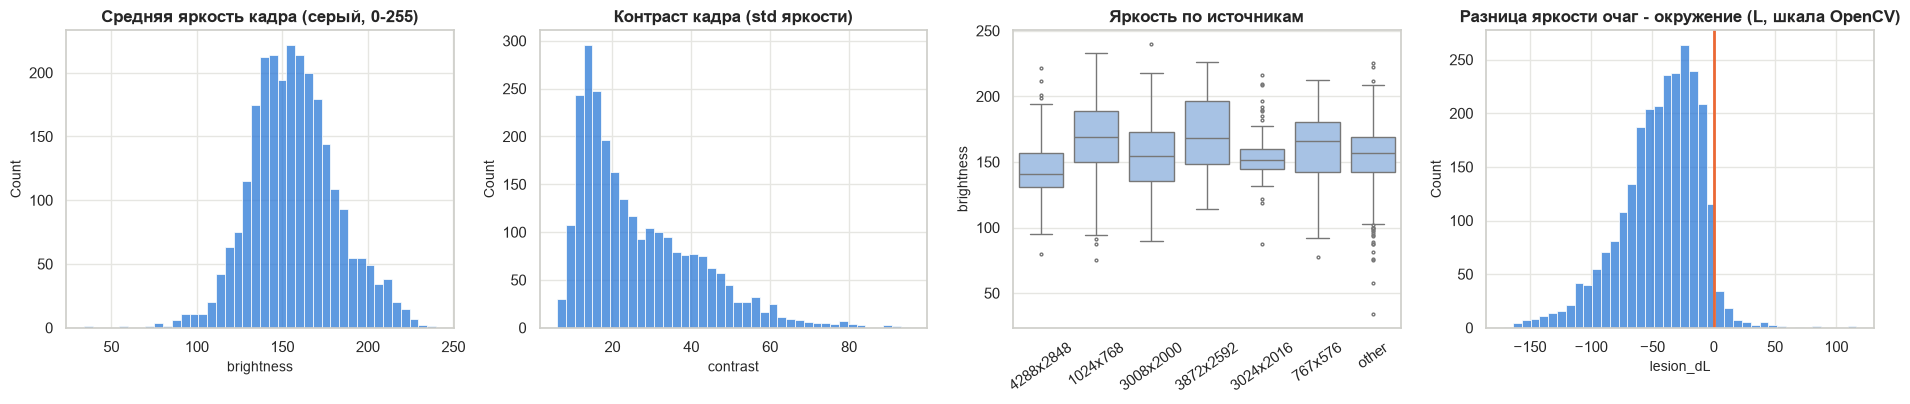

Яркость: медиана 156, 5-й / 95-й перцентили 118 / 202
Тёмные кадры (< 100): 36 (1.4%); светлые (> 200): 153 (5.9%)
Низкоконтрастные кадры (std < 10): 114 (4.4%)
Очаг темнее окружения: 96.5%; ΔLab очаг/окружение: медиана 43.3, 10% самых слабых < 14.1
Spearman(яркость, контраст) = +0.135


,brightness,contrast,lesion_delta_lab
source,,,
4288x2848,140.9,14.1,26.1
1024x768,169.1,26.4,42.4
3008x2000,154.8,15.2,42.8
3872x2592,168.5,16.3,35.7
3024x2016,151.8,15.3,32.0
767x576,166.1,42.5,46.7
other,156.7,38.3,68.1


In [35]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
sns.histplot(df["brightness"], bins=40, color=BLUE, edgecolor="white", ax=axes[0])
axes[0].set_title("Средняя яркость кадра (серый, 0-255)")
sns.histplot(df["contrast"], bins=40, color=BLUE, edgecolor="white", ax=axes[1])
axes[1].set_title("Контраст кадра (std яркости)")
sns.boxplot(data=df, x="source", y="brightness", order=SOURCE_ORDER, color="#9dc1ee", fliersize=2, ax=axes[2])
axes[2].set_title("Яркость по источникам")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=35)
sns.histplot(df["lesion_dL"], bins=40, color=BLUE, edgecolor="white", ax=axes[3])
axes[3].axvline(0, color=ORANGE, lw=2)
axes[3].set_title("Разница яркости очаг - окружение (L, шкала OpenCV)")
plt.tight_layout()
plt.show()

print(f"Яркость: медиана {df['brightness'].median():.0f}, 5-й / 95-й перцентили {df['brightness'].quantile(.05):.0f} / {df['brightness'].quantile(.95):.0f}")
print(f"Тёмные кадры (< 100): {(df['brightness'] < 100).sum()} ({(df['brightness'] < 100).mean():.1%}); "
      f"светлые (> 200): {(df['brightness'] > 200).sum()} ({(df['brightness'] > 200).mean():.1%})")
print(f"Низкоконтрастные кадры (std < 10): {(df['contrast'] < 10).sum()} ({(df['contrast'] < 10).mean():.1%})")
print(f"Очаг темнее окружения: {(df['lesion_dL'] < 0).mean():.1%}; ΔLab очаг/окружение: медиана {df['lesion_delta_lab'].median():.1f}, "
      f"10% самых слабых < {df['lesion_delta_lab'].quantile(.1):.1f}")
print(f"Spearman(яркость, контраст) = {spearman(df['brightness'], df['contrast']):+.3f}")
display(df.groupby("source")[["brightness", "contrast", "lesion_delta_lab"]].median().reindex(SOURCE_ORDER).round(1))

> Яркость в основном 118-202 (медиана 156); тёмных (<100) 1.4%, светлых (>200) 5.9%; низкоконтрастных (std <10) 4.4%. **Контраст зависит от источника:** 14-16 у больших камер против 26 у 1024x768 и 38-42 у 767x576 и `other`. Яркость отличается меньше (141-169). Очаг темнее окружения в 96.5% случаев; контраст очаг/окружение (ΔLab) от 26 у 4288x2848 до 68 у `other`.

## 6. Цвет

Нормализация датасета: mean = [0.709, 0.582, 0.536], std = [0.156, 0.165, 0.18]
(ImageNet: mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225])


,весь кадр,только фон,белый (1/√3)
R,0.652,0.646,0.577
G,0.549,0.551,0.577
B,0.518,0.523,0.577


Spearman(illum_r, площадь очага): весь кадр -0.019, только фон -0.148


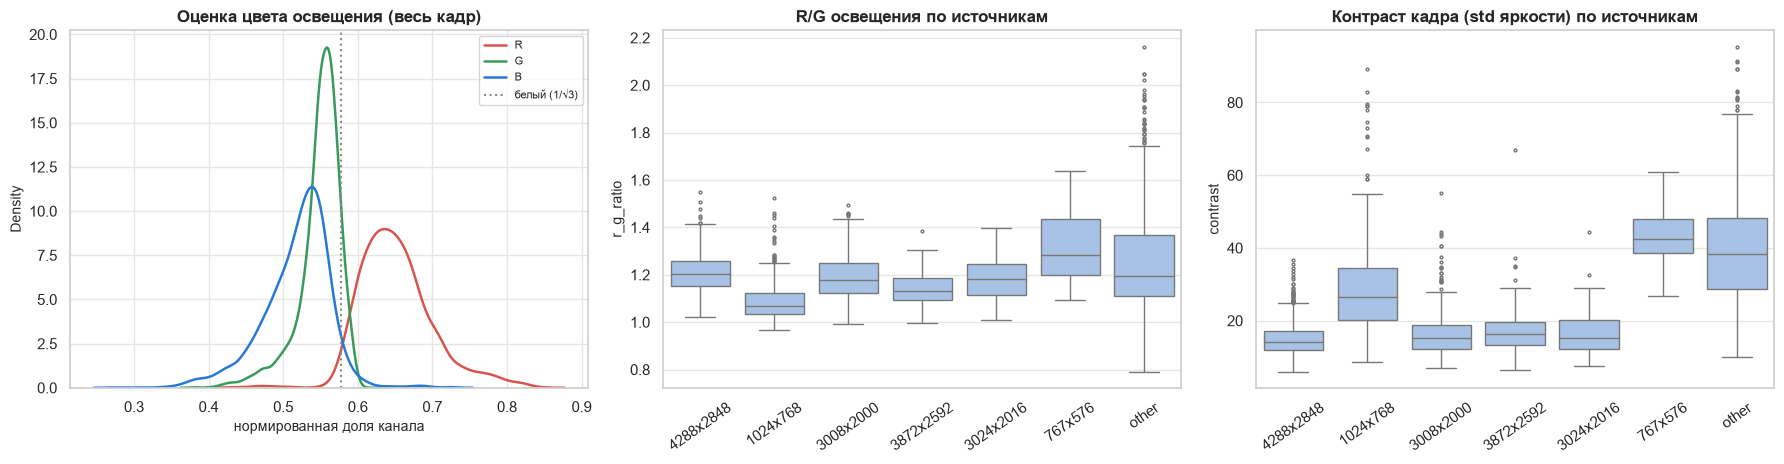


η² - какая доля дисперсии признака объясняется источником (разрешением):
contrast           0.488
lesion_area_pct    0.260
r_g_ratio          0.171
brightness         0.141
hair_bg_frac       0.122
blur_lapvar        0.104
corner_dark        0.028


,lesion_area_pct,r_g_ratio,brightness,contrast,n
source,,,,,
4288x2848,5.540,1.202,140.877,14.100,558
1024x768,24.805,1.070,169.128,26.431,556
3008x2000,4.281,1.177,154.782,15.164,379
3872x2592,3.869,1.132,168.532,16.271,125
3024x2016,6.868,1.181,151.838,15.307,100
767x576,23.250,1.282,166.073,42.485,63
other,27.197,1.193,156.707,38.253,813


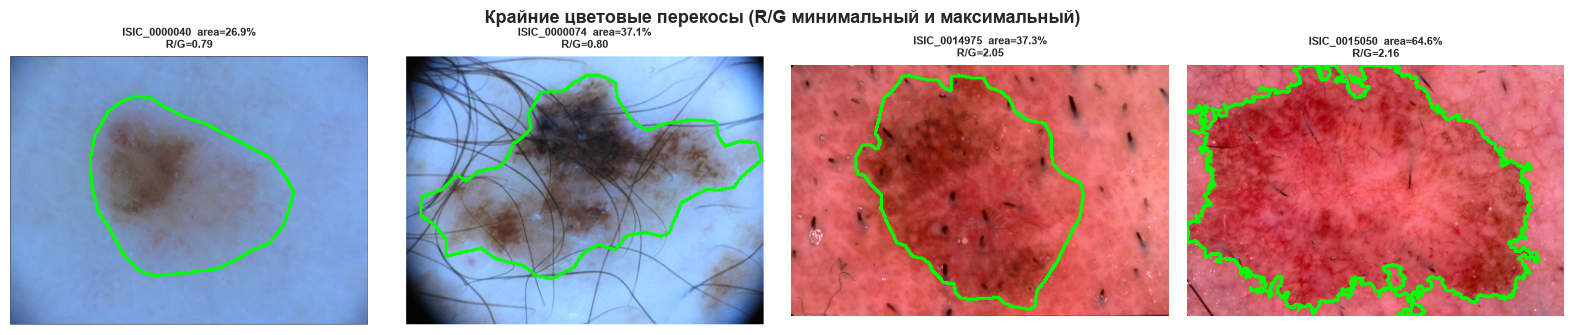

In [36]:
# 1. Статистики для нормализации входа сети (RGB, диапазон 0-1) - считаем по уменьшенным кадрам
mean_rgb = df[["mean_r", "mean_g", "mean_b"]].mean().values
# общая std = sqrt(среднее дисперсий + дисперсия средних)
std_rgb = np.sqrt((df[["std_r", "std_g", "std_b"]] ** 2).mean().values + df[["mean_r", "mean_g", "mean_b"]].var(ddof=0).values)
print(f"Нормализация датасета: mean = {np.round(mean_rgb, 3).tolist()}, std = {np.round(std_rgb, 3).tolist()}")
print("(ImageNet: mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225])")

# 2. Сдвиг освещения: весь кадр vs только фон
cmp = pd.DataFrame({"весь кадр": df[["illum_r", "illum_g", "illum_b"]].mean().values,
                    "только фон": df[["illum_bg_r", "illum_bg_g", "illum_bg_b"]].mean().values,
                    "белый (1/√3)": 1 / np.sqrt(3)}, index=["R", "G", "B"])
display(cmp.round(3))
print(f"Spearman(illum_r, площадь очага): весь кадр {spearman(df['illum_r'], df['lesion_area_pct']):+.3f}, "
      f"только фон {spearman(df['illum_bg_r'], df['lesion_area_pct']):+.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for col, lab, c in (("illum_r", "R", "#d9534f"), ("illum_g", "G", "#3a9a5b"), ("illum_b", "B", BLUE)):
    sns.kdeplot(df[col], color=c, label=lab, lw=1.8, ax=axes[0])
axes[0].axvline(1 / np.sqrt(3), color=GRAY, ls=":", label="белый (1/√3)")
axes[0].set_title("Оценка цвета освещения (весь кадр)")
axes[0].set_xlabel("нормированная доля канала")
axes[0].legend(fontsize=8)

sns.boxplot(data=df, x="source", y="r_g_ratio", order=SOURCE_ORDER, color="#9dc1ee", fliersize=2, ax=axes[1])
axes[1].set_title("R/G освещения по источникам")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=35)

sns.boxplot(data=df, x="source", y="contrast", order=SOURCE_ORDER, color="#9dc1ee", fliersize=2, ax=axes[2])
axes[2].set_title("Контраст кадра (std яркости) по источникам")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

# 3. Насколько источник «объясняет» признак? (доля межгрупповой дисперсии, η²)
def eta_squared(col):
    d = df[[col, "source"]].dropna()
    return d.groupby("source")[col].apply(lambda s: len(s) * (s.mean() - d[col].mean()) ** 2).sum() / ((d[col] - d[col].mean()) ** 2).sum()

eta = pd.Series({c: eta_squared(c) for c in ["lesion_area_pct", "r_g_ratio", "brightness", "contrast", "blur_lapvar", "hair_bg_frac", "corner_dark"]})
print("\nη² - какая доля дисперсии признака объясняется источником (разрешением):")
print(eta.round(3).sort_values(ascending=False).to_string())
display(df.groupby("source")[["lesion_area_pct", "r_g_ratio", "brightness", "contrast"]].median().reindex(SOURCE_ORDER).round(3)
        .join(df["source"].value_counts().rename("n")))

# Кадры с крайними значениями R/G (без коррекции)
by_rg = df.sort_values("r_g_ratio")
show_grid(pd.concat([by_rg.head(2), by_rg.tail(2)]), "Крайние цветовые перекосы (R/G минимальный и максимальный)",
          subtitle=lambda r: f"R/G={r.r_g_ratio:.2f}")

> - Оценка освещения сдвинута в красное (R = 0.65 при «белом» 0.577), и на фоне без очага почти так же (0.646): это не артефакт очага, но цвет лампы и цвет кожи по картинкам не разделить.
> - Перекосы идут в обе стороны: R/G от 0.8 (синий) до 2.2 (красный) при медиане 1.17; медиана по источникам от 1.07 (1024x768) до 1.28 (767x576).
> - Источник объясняет заметную часть дисперсии: η² 0.49 для контраста, 0.26 для площади очага, 0.17 для R/G, 0.14 для яркости.
> - Статистики датасета: mean = [0.709, 0.582, 0.536], std = [0.156, 0.165, 0.180] (ImageNet: [0.485, 0.456, 0.406] / [0.229, 0.224, 0.225]).

## 7. Артефакты

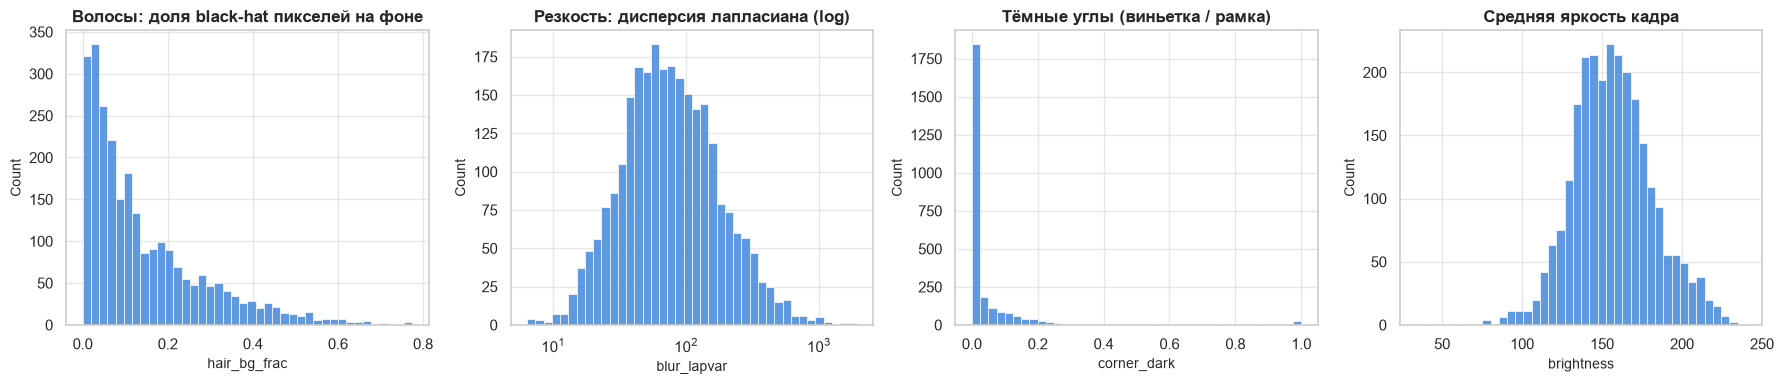

Кадров с тёмными углами (>20% углового патча): 158 (6.1%)
Кадров с заметными волосами (верхний дециль hair_bg_frac): порог = 0.347
Spearman с площадью очага (проверка, не загрязнён ли прокси очагом):
hair_bg_frac    0.004
blur_lapvar     0.098
corner_dark    -0.131
brightness      0.003


,hair_bg_frac,blur_lapvar,corner_dark
source,,,
4288x2848,0.086,50.768,0.064
1024x768,0.038,54.105,0.000
3008x2000,0.100,76.595,0.000
3872x2592,0.123,141.038,0.029
3024x2016,0.146,83.833,0.000
767x576,0.208,306.030,0.030
other,0.163,97.276,0.001


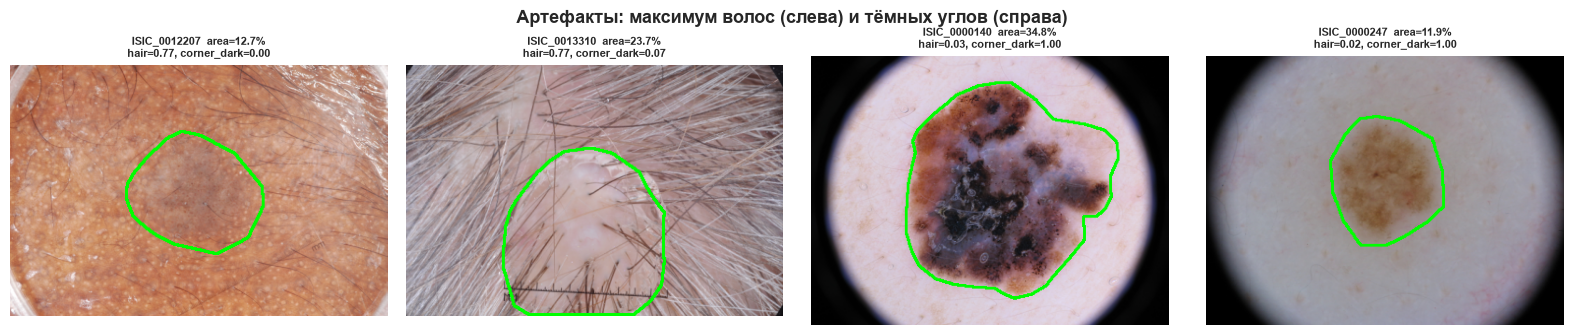

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
sns.histplot(df["hair_bg_frac"].dropna(), bins=40, color=BLUE, edgecolor="white", ax=axes[0])
axes[0].set_title("Волосы: доля black-hat пикселей на фоне")
sns.histplot(df["blur_lapvar"], bins=40, log_scale=True, color=BLUE, edgecolor="white", ax=axes[1])
axes[1].set_title("Резкость: дисперсия лапласиана (log)")
sns.histplot(df["corner_dark"], bins=40, color=BLUE, edgecolor="white", ax=axes[2])
axes[2].set_title("Тёмные углы (виньетка / рамка)")
sns.histplot(df["brightness"], bins=40, color=BLUE, edgecolor="white", ax=axes[3])
axes[3].set_title("Средняя яркость кадра")
plt.tight_layout()
plt.show()

print(f"Кадров с тёмными углами (>20% углового патча): {(df['corner_dark'] > 0.2).sum()} ({(df['corner_dark'] > 0.2).mean():.1%})")
print(f"Кадров с заметными волосами (верхний дециль hair_bg_frac): порог = {df['hair_bg_frac'].quantile(.9):.3f}")
print("Spearman с площадью очага (проверка, не загрязнён ли прокси очагом):")
print(pd.Series({c: spearman(df[c], df["lesion_area_pct"]) for c in ["hair_bg_frac", "blur_lapvar", "corner_dark", "brightness"]}).round(3).to_string())
display(df.groupby("source")[["hair_bg_frac", "blur_lapvar", "corner_dark"]].median().reindex(SOURCE_ORDER).round(3))
show_grid(pd.concat([df.nlargest(2, "hair_bg_frac"), df.nlargest(2, "corner_dark")]), "Артефакты: максимум волос (слева) и тёмных углов (справа)",
          subtitle=lambda r: f"hair={r.hair_bg_frac:.2f}, corner_dark={r.corner_dark:.2f}")

> Показатель волос считается по фону вдали от очага и не коррелирует с площадью очага (ρ = 0.004); визуально максимум - скальповые снимки. Доля волос зависит от источника (медиана 0.04 у 1024x768, 0.21 у 767x576). У 6.1% кадров тёмные углы (виньетка или рамка дерматоскопа). На кадрах также встречаются линейки и цветные метки.

## 8. Дубликаты

Пар с расстоянием Хэмминга <= 0: 4
Пар с расстоянием Хэмминга <= 1: 13
Пар с расстоянием Хэмминга <= 2: 30
Пар с расстоянием Хэмминга <= 3: 113
Пар с расстоянием Хэмминга <= 4: 281

Кандидатов в дубликаты (dist <= 2): 30
Групп с > 1 кадром: 20, кадров в таких группах: 49, макс. размер группы: 6


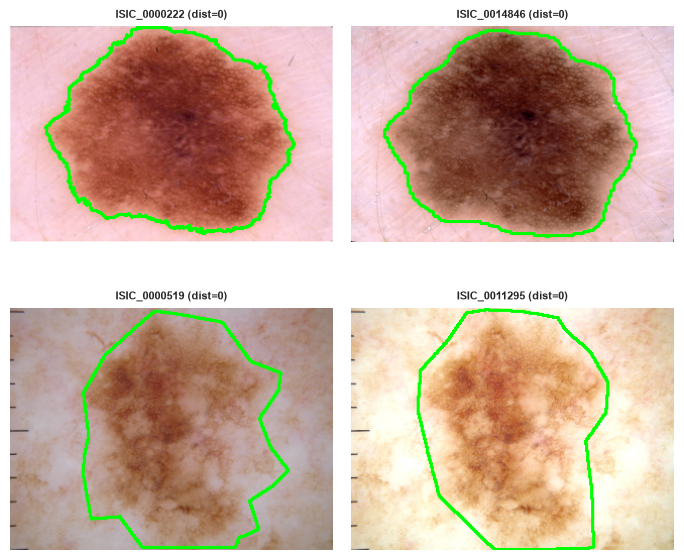

In [38]:
# Поиск дубликатов / почти-дубликатов по dHash (64 бит)
hashes = np.array([int(h, 16) for h in df["dhash"]], dtype=np.uint64)
hash_bytes = hashes.view(np.uint8).reshape(-1, 8)
popcount = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
dist = popcount[hash_bytes[:, None, :] ^ hash_bytes[None, :, :]].sum(axis=2)
iu = np.triu_indices(len(df), k=1)
pair_dist = dist[iu]
for thr in (0, 1, 2, 3, 4):
    print(f"Пар с расстоянием Хэмминга <= {thr}: {(pair_dist <= thr).sum()}")

DUP_THR = 2  # при 3-4 на ручной проверке уже встречались разные снимки
close = pair_dist <= DUP_THR
dup_pairs = pd.DataFrame({"id_a": df["id"].values[iu[0][close]], "id_b": df["id"].values[iu[1][close]],
                          "dist": pair_dist[close]}).sort_values("dist")
print(f"\nКандидатов в дубликаты (dist <= {DUP_THR}): {len(dup_pairs)}")

# Группы связности (union-find): кадры одной группы должны попасть в один сплит
parent = {i: i for i in df["id"]}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for a, b in zip(dup_pairs["id_a"], dup_pairs["id_b"]):
    parent[find(a)] = find(b)
df["dup_group"] = df["id"].map(find)
group_sizes = df["dup_group"].value_counts()
print(f"Групп с > 1 кадром: {(group_sizes > 1).sum()}, кадров в таких группах: {int(group_sizes[group_sizes > 1].sum())}, макс. размер группы: {group_sizes.max()}")

# Визуальная проверка лучших кандидатов
sample = dup_pairs.head(2)
fig, axes = plt.subplots(len(sample), 2, figsize=(7, 3.2 * len(sample)), squeeze=False)
for i, p in enumerate(sample.itertuples(index=False)):
    for j, id_ in enumerate((p.id_a, p.id_b)):
        axes[i, j].imshow(load_preview(df.loc[df["id"] == id_].iloc[0], max_side=320))
        axes[i, j].set_title(f"{id_} (dist={p.dist})", fontsize=8)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

> По dHash 4 пары совпадают полностью, 13 отличаются на ≤1 бит, 30 на ≤2. Ручная проверка (отдельный прогон по тем же хешам): при расстоянии 0 - дубли одного очага, иногда с другой цветопередачей; при 3-4 уже встречались разные снимки, поэтому порог 2. Итого 20 групп, 49 кадров (1.9%), максимальная группа - 6. Это нижняя оценка: dHash не ловит дубли с поворотом или другим кропом.

## 9. Нормализация размеров

**Решение:** масштабировать кадр так, чтобы **короткая сторона = S** (пропорции сохраняются), затем вырезать случайный квадрат S x S (`RandomCrop`, z = 1: режется только длинная сторона).

**Почему так (по данным EDA):** разрешения очень разные (0.38-30 Мп), но почти все кадры с соотношением сторон 1.33-1.5, то есть в квадрат попадает 67-75% кадра; форма очага не искажается; пустых полей нет; очаг получается крупнее, чем при вписывании всего кадра в квадрат. Риск один - кроп может срезать часть очага (крупного или у края кадра), поэтому кроп делается **одинаковым для картинки и маски**, а позиция выбирается заново, если в кропе осталось меньше 90% очага. Ниже - функции и проверка на 150 парах при S = 256.

100%|██████████| 150/150 [00:17<00:00,  8.41it/s]


,средняя доля очага в кропе,кропов с потерей >10% очага,кропов с потерей >50% очага
без повторной выборки,0.964,15.7%,0.13%
с повторной выборкой (min_keep=0.9),0.978,6.8%,0.0%


Проверено 150 пар x 20 кропов: форма (S, S), маска остаётся бинарной


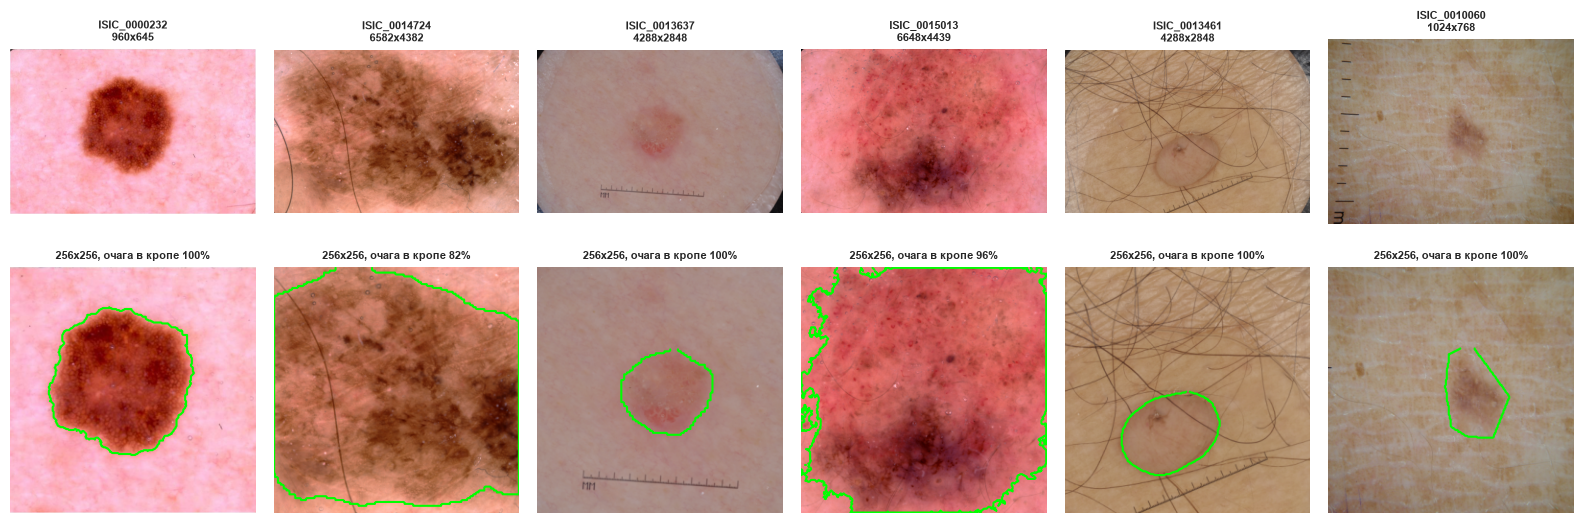

In [39]:
S = 256  # размер входа (сторона квадрата), px


def resize_short_side(img, mask, size=S):
    """Короткая сторона -> size, пропорции сохраняются (изображение: INTER_AREA при уменьшении, маска: nearest)."""
    h, w = img.shape[:2]
    scale = size / min(h, w)
    nw, nh = max(size, round(w * scale)), max(size, round(h * scale))
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return (cv2.resize(img, (nw, nh), interpolation=interp),
            cv2.resize(mask, (nw, nh), interpolation=cv2.INTER_NEAREST))


def random_crop(img, mask, size=S, min_keep=0.9, max_tries=10, rng=None):
    """Случайный кроп size x size одинаковый для картинки и маски (z = 1: режется только длинная сторона).
    Если в кропе осталось < min_keep очага, позиция выбирается заново (до max_tries попыток, берётся лучшая)."""
    rng = rng or np.random.default_rng()
    h, w = mask.shape
    total = mask.sum()
    best = None
    for _ in range(max_tries):
        y0, x0 = int(rng.integers(0, h - size + 1)), int(rng.integers(0, w - size + 1))
        keep = mask[y0:y0 + size, x0:x0 + size].sum() / total if total else 1.0
        if best is None or keep > best[0]:
            best = (keep, y0, x0)
        if keep >= min_keep:
            break
    keep, y0, x0 = best
    return img[y0:y0 + size, x0:x0 + size], mask[y0:y0 + size, x0:x0 + size], keep


def random_crop_pair(img_bgr, mask, size=S, **kw):
    """Полная функция нормализации размера: resize короткой стороны + RandomCrop."""
    img, msk = resize_short_side(img_bgr, mask.astype(np.uint8), size)
    return random_crop(img, msk, size, **kw)


# Проверка на 150 случайных парах: по 20 случайных кропов, без повторной выборки (1 попытка) и с ней
rng = np.random.default_rng(RANDOM_STATE)
check = df.sample(150, random_state=RANDOM_STATE)
keeps = {"без повторной выборки": [], "с повторной выборкой (min_keep=0.9)": []}
for row in tqdm(check.itertuples(index=False), total=len(check)):
    img = read_image_reduced(row.image_path, row.width, row.height, target=ANALYSIS_SIDE)
    mask = (cv2.imread(row.mask_path, cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
    mask = cv2.resize(mask, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
    img_r, msk_r = resize_short_side(img, mask, S)
    for _ in range(20):
        x, y, k = random_crop(img_r, msk_r, S, max_tries=1, rng=rng)
        assert x.shape == (S, S, 3) and y.shape == (S, S) and set(np.unique(y).tolist()) <= {0, 1}
        keeps["без повторной выборки"].append(k)
        x, y, k = random_crop(img_r, msk_r, S, min_keep=0.9, max_tries=10, rng=rng)
        keeps["с повторной выборкой (min_keep=0.9)"].append(k)

summary = pd.DataFrame({name: {"средняя доля очага в кропе": np.mean(v), "кропов с потерей >10% очага": np.mean(np.array(v) < 0.9),
                               "кропов с потерей >50% очага": np.mean(np.array(v) < 0.5)}
                        for name, v in keeps.items()}).T
summary["кропов с потерей >10% очага"] = (summary["кропов с потерей >10% очага"] * 100).round(1).astype(str) + "%"
summary["кропов с потерей >50% очага"] = (summary["кропов с потерей >50% очага"] * 100).round(2).astype(str) + "%"
display(summary.round({"средняя доля очага в кропе": 3}))
print(f"Проверено {len(check)} пар x 20 кропов: форма (S, S), маска остаётся бинарной")

fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for j, row in enumerate(check.head(6).itertuples(index=False)):
    img = read_image_reduced(row.image_path, row.width, row.height, target=ANALYSIS_SIDE)
    mask = (cv2.imread(row.mask_path, cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
    mask = cv2.resize(mask, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
    x, y, k = random_crop_pair(img, mask, rng=rng)
    axes[0, j].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0, j].set_title(f"{row.id}\n{row.width}x{row.height}", fontsize=8)
    axes[1, j].imshow(cv2.cvtColor(x, cv2.COLOR_BGR2RGB))
    for c in cv2.findContours(y, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
        axes[1, j].plot(c[:, 0, 0], c[:, 0, 1], color="#00ff00", lw=1.5)
    axes[1, j].set_title(f"{S}x{S}, очага в кропе {k:.0%}", fontsize=8)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout()
plt.show()

> **Проверка:** без повторной выборки в кропе остаётся в среднем 96.4% очага; 15.7% кропов теряют больше 10% очага, 0.13% - больше половины. С повторной выборкой: 97.8% в среднем, больше 10% теряют 6.8% кропов, больше половины - ни один. Оставшиеся потери, вероятно, у крупных очагов, которые не помещаются в квадрат целиком. Функции возвращают квадраты (S, S), маска остаётся бинарной.
> **Для валидации и инференса** случайность не нужна: можно подавать кадр целиком после масштабирования короткой стороны к S (прямоугольный вход) или брать центральный кроп.

## 10. Нормализация цвета и яркости

**Зачем:** в разделах 5-6 видно, что цвет освещения сильно разный (R/G 0.8-2.2) и зависит от источника съёмки. Сеть может выучить «камеру» вместо очага.

**Цвет - Shades of Gray** (p = 6): используем тот же оценщик освещения, что и в EDA. Каждый канал домножается на `(1/√3) / illum_c`, чтобы освещение стало нейтральным (серым). Усиление ограничено диапазоном [0.6, 1.6], чтобы не раздувать шум на сильных перекосах.

**Яркость:** отдельной коррекции не делаем - проверим на данных, нужна ли она.

Проверяем на 300 случайных кадрах: стал ли разброс R/G, яркости и контраста меньше. Коррекция применяется к **изображению** (маска не меняется) и идёт **до** нормализации mean/std из раздела 6 - эти статистики нужно пересчитать на скорректированных кадрах.

  0%|          | 0/300 [00:00<?, ?it/s]

100%|██████████| 300/300 [00:49<00:00,  6.08it/s]


исходные  после SoG
R/G      std              0.163      0.002
         η² источника     0.282      0.132
яркость  std             24.094     23.603
         η² источника     0.090      0.079
контраст std             14.656     15.147
         η² источника     0.523      0.542

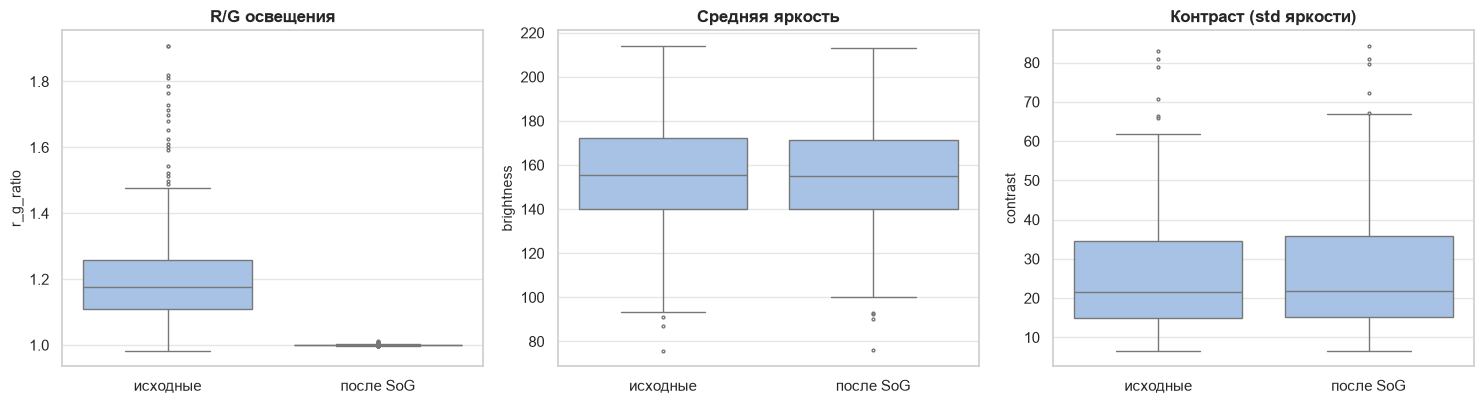

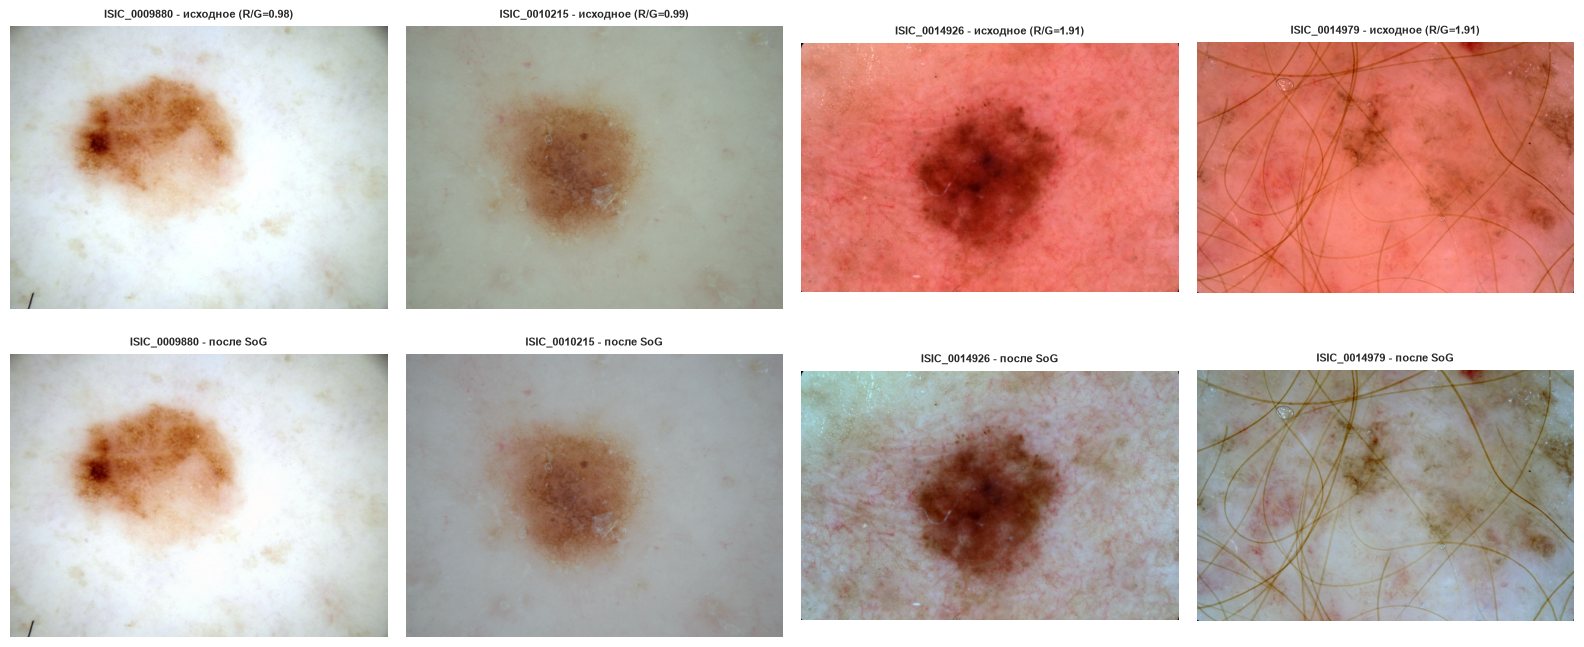

In [40]:
GAIN_MIN, GAIN_MAX = 0.6, 1.6


def shades_of_gray(img_bgr, p=6):
    """Цветовая константность: делаем оценку освещения нейтральной (серой). Вход/выход: uint8 BGR."""
    r, g, b = estimate_illumination(img_bgr, p=p)
    gain = np.clip((1 / np.sqrt(3)) / np.array([b, g, r]), GAIN_MIN, GAIN_MAX)  # порядок BGR
    return np.clip(img_bgr.astype(np.float32) * gain, 0, 255).astype(np.uint8)


def stats(img_bgr):
    r, g, _ = estimate_illumination(img_bgr)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    return {"r_g_ratio": r / g, "brightness": gray.mean(), "contrast": gray.std()}


norm_sample = df.sample(300, random_state=RANDOM_STATE)
rows = []
for row in tqdm(norm_sample.itertuples(index=False), total=len(norm_sample)):
    img = read_image_reduced(row.image_path, row.width, row.height, target=ANALYSIS_SIDE)
    for name, out in (("исходные", img), ("после SoG", shades_of_gray(img))):
        rows.append({"id": row.id, "source": row.source, "variant": name, **stats(out)})
df_norm = pd.DataFrame(rows)


def eta2(d, col):
    m = d[col].mean()
    return d.groupby("source")[col].apply(lambda s: len(s) * (s.mean() - m) ** 2).sum() / ((d[col] - m) ** 2).sum()


report = {}
for name, d in df_norm.groupby("variant", sort=False):
    for col, label in (("r_g_ratio", "R/G"), ("brightness", "яркость"), ("contrast", "контраст")):
        report.setdefault((label, "std"), {})[name] = d[col].std()
        report.setdefault((label, "η² источника"), {})[name] = eta2(d, col)
display(pd.DataFrame(report).T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, title in zip(axes, ["r_g_ratio", "brightness", "contrast"],
                          ["R/G освещения", "Средняя яркость", "Контраст (std яркости)"]):
    sns.boxplot(data=df_norm, x="variant", y=col, color="#9dc1ee", fliersize=2, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

# До / после на кадрах с самыми сильными перекосами цвета
ex = norm_sample.sort_values("r_g_ratio")
ex = pd.concat([ex.head(2), ex.tail(2)])
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, row in enumerate(ex.itertuples(index=False)):
    img = read_image_reduced(row.image_path, row.width, row.height, target=384)
    for i, (name, im) in enumerate((("исходное", img), ("после SoG", shades_of_gray(img)))):
        axes[i, j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        axes[i, j].set_title(f"{row.id} - {name}" + (f" (R/G={row.r_g_ratio:.2f})" if i == 0 else ""), fontsize=8)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

> **Результат (300 кадров):**
> - Разброс цвета R/G сильно уменьшился: std 0.163 -> 0.002. Но цифра почти тавтологична: проверяли тем же оценщиком, которым корректировали. Настоящую пользу покажут картинки выше и метрики модели.
> - Яркость и контраст почти не изменились (std яркости 24.1 -> 23.6, контраста 14.7 -> 15.1). Зависимость от источника тоже осталась прежней (η² контраста 0.52 -> 0.54).
>
> **Вывод:** используем Shades of Gray для цвета. Отдельная коррекция яркости не нужна: она и так мало зависит от источника (η² = 0.09), хватит обычной нормализации mean/std. Разницу между камерами по контрасту лучше закрывать аугментациями (яркость/контраст, blur, шум). Пользу SoG стоит проверить на модели: обучить с ним и без него.

## 11. Итоги: что нормализовать

**Данные чистые:** 2594 пары, размеры совпадают, маски бинарные и без пустых; дефектов мало (14 мульти-компонентных масок, 24 с дырами, 49 кадров в 20 группах дубликатов).

| Что в данных | Что показало EDA | Нужна нормализация |
|---|---|---|
| Размер кадра | 206 разрешений, 0.38-30 Мп, aspect в основном 1.33-1.5 | **короткая сторона = S + RandomCrop (z=1)**, кроп по маске (раздел 9) |
| Размер очага | 0.3-98.7% кадра, 24% <5%; 10% касаются границы; центры у середины | учитывать при уменьшении (мелкие очаги) и при кропах/сдвигах |
| Яркость и контраст | контраст сильно зависит от источника (η² 0.49), яркость - слабо (η² 0.09) | отдельная коррекция не нужна; mean/std + аугментации |
| Цвет | сдвиг в красное, перекосы R/G 0.8-2.2, зависимость от источника | **Shades of Gray** (раздел 10), затем свои mean/std, пересчитанные после коррекции |
| Артефакты | волосы, виньетка (6%), линейки и метки | не убираются цветовой нормализацией |
| Дубликаты | 49 кадров в 20 группах | удалить или держать вместе |

**Порядок предобработки:** resize короткой стороны -> RandomCrop (картинка и маска) -> Shades of Gray -> mean/std нормализация.

**Решение по размеру:** короткая сторона = S + `RandomCrop` с одинаковой позицией для картинки и маски и повторной выборкой, если осталось <90% очага.

**Ограничения:** проверка кропа сделана на 150 парах и уменьшенных кадрах (S = 256), цвета - на 300 кадрах; «источник» определён по разрешению, а не по метаданным; оценка освещения эвристическая (цвет лампы и цвет кожи не разделены), а эффект SoG измерен тем же оценщиком, поэтому нужен ablation на модели; показатель волос - прокси с вручную подобранным порогом; дубликаты - нижняя оценка.